In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def RFL_model(parameters, states, pr, dt): 
    #ribosome flow model, original equations with the simplification that all elongation rates are homogeneous β
    
    #states are ocupation probabilities
    
    if states.shape[0] != parameters['l']: 
        raise ValueError('Number of states incompatible with gene length')
    
    
    new_states = np.zeros(states.shape)
    new_states[0] = states[0] + (parameters['α']*(1 - states[0])*pr - parameters['β']* states[0] * (1-states[1]))*dt
    for n in range(1, parameters['l']-1): 
        new_states[n] = states[n]+ (parameters['β']* states[n-1] * (1- states[n]) - parameters['β']* states[n] * (1-states[n+1]))*dt
    new_states[-1] = states[-1] + (parameters['β']* (states[-2]* (1-states[-1]) - states[-1]))*dt
    pr = pr + (-parameters['α']*(1 - states[0])*pr + parameters['β']* states[-1])*dt
    
    return new_states, pr

        
def simulation_wrapper(state0,pr0, params, update, sim_time, dt): 
    #euler method to see behaviour quickly
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0]])
    states[0,:] = state0
    ribosomes = np.zeros([int(sim_time/dt)+1])
    ribosomes[0] = pr0
    
    for t in range(int(sim_time/dt)): 
        states[t+1], ribosomes[t+1] = update(params, states[t],ribosomes[t], dt)
        
    return states, ribosomes

In [3]:
α = 0.5 #ribosomal flow (initiation)
β = .5 #homogeneous elongation or transfer rates
l = 25 #in codons
pr0 = 0.1

parameters = dict()
parameters['α'] = α
parameters['β'] = β
parameters['l'] = l

sim_time = 800
dt = 0.001



init_states = np.zeros([l])

sim_res, rb = simulation_wrapper(init_states,pr0, parameters, RFL_model,sim_time, dt)

l = 50
parameters['l'] = l
init_states = np.zeros([l])
sim_res_long, rb_long = simulation_wrapper(init_states, pr0, parameters, RFL_model,sim_time, dt)

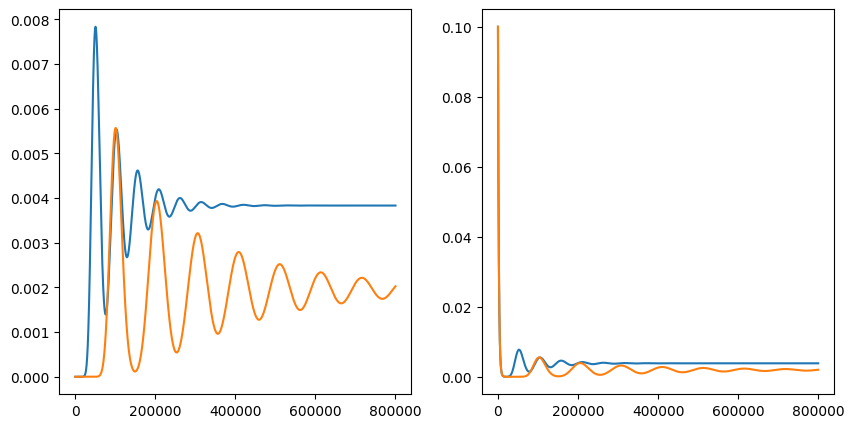

In [4]:
#plot first results, just seeing how it looks: 
#-1 is the produced protein at that point or rather the occupation for the last codon group

fig, ax = plt.subplots(1,2, figsize = (10,5))
ax[0].plot(sim_res[:,-1])
ax[0].plot(sim_res_long[:,-1])
ax[1].plot(rb[:])
ax[1].plot(rb_long[:])
plt.show()

In [5]:
#length dependence

Ls = np.arange(2,51, 1)
res = np.zeros(Ls.shape)
ribs = np.zeros(Ls.shape)
for l in range(Ls.shape[0]): 
    parameters['l'] = Ls[l]
    init_states = np.zeros([Ls[l]])
    sim_res, ribos = simulation_wrapper(init_states,pr0, parameters, RFL_model,sim_time, dt)
    res[l] = sim_res[-1,-1] #looking at the occupation probability of the last codon group
    ribs[l] = ribos[-1]
    


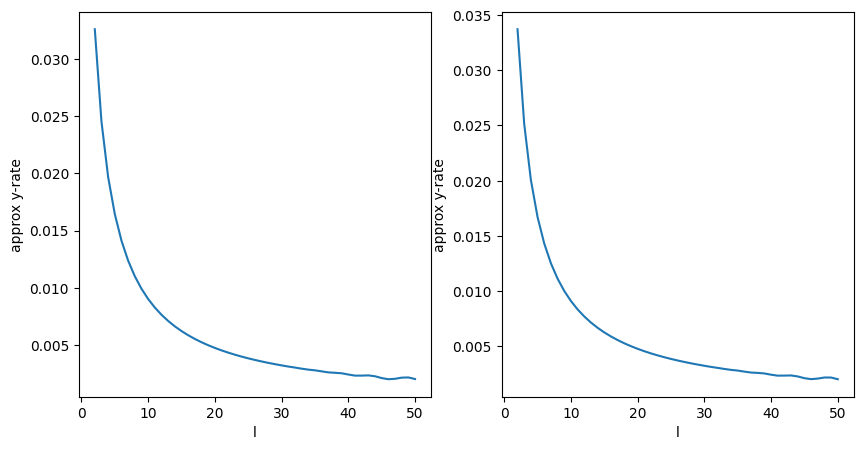

In [6]:
fig, ax = plt.subplots(1,2, figsize = (10,5))
ax[0].plot(Ls, res) #think about how to do this more reasonable
ax[1].plot(Ls, ribs)
ax[0].set_xlabel('l')
ax[0].set_ylabel('approx y-rate')
ax[1].set_xlabel('l')
ax[1].set_ylabel('approx y-rate')
plt.show()

In [7]:
#####all above is with non interacting terms for the ribosome probability
def RFL_model(parameters, states, pr, dt): 
    #ribosome flow model, original equations with the simplification that all elongation rates are homogeneous β
    
    #states are ocupation probabilities
        
    if states.shape[0] != parameters['l'].shape[0]: 
        raise ValueError('Number of genes incompatible')
    
    
    new_states = np.zeros(states.shape)
    new_states[:,0] = states[:,0] + (parameters['α']*(1 - states[:,0])*pr - parameters['β']* states[:,0] * (1-states[:,1]))*dt
    for n in range(1, np.max(parameters['l'])-1): 
        new_states[:,n] = states[:,n]+ (parameters['β']* states[:,n-1] * (1- states[:,n]) - parameters['β']* states[:,n] * (1-states[:,n+1]))*dt
    new_states[:,parameters['l']-1] = states[:,parameters['l']-1] + (parameters['β']* (states[:,parameters['l']-2]* (1-states[:,parameters['l']-1]) - states[:,parameters['l']-1]))*dt
    pr = pr + (-parameters['α']*np.mean((1 - states[:,0]))*pr + parameters['β']* np.mean(states[:,parameters['l']-1]))*dt
    
    return new_states, pr

        
def simulation_wrapper(state0,pr0, params, update, sim_time, dt): 
    #euler method to see behaviour quickly
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0], state0.shape[1]])
    states[0,:] = state0
    ribosomes = np.zeros([int(sim_time/dt)+1])
    ribosomes[0] = pr0
    
    for t in range(int(sim_time/dt)): 
        states[t+1], ribosomes[t+1] = update(params, states[t],ribosomes[t], dt)
        
    return states, ribosomes

In [8]:
α = 0.5 #ribosomal flow (initiation)
β = .5 #homogeneous elongation or transfer rates
l = np.array([25,50]) #in codons
pr0 = 0.1

parameters = dict()
parameters['α'] = α
parameters['β'] = β
parameters['l'] = l

sim_time = 800
dt = 0.001



init_states = np.zeros([l.shape[0], np.max(l)])

sim_res, rb = simulation_wrapper(init_states,pr0, parameters, RFL_model,sim_time, dt)


pr0 = 0.5
high_sim_res, high_rb = simulation_wrapper(init_states,pr0, parameters, RFL_model,sim_time, dt)




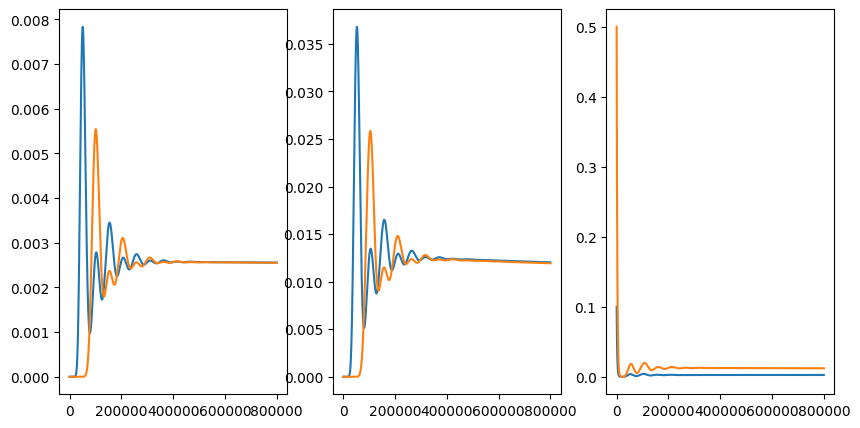

In [9]:
#plot first results, just seeing how it looks: 
#-1 is the produced protein at that point or rather the occupation for the last codon group

fig, ax = plt.subplots(1,3, figsize = (15,5))
ax[0].plot(sim_res[:,0,parameters['l'][0]-1])
ax[0].plot(sim_res[:,1,parameters['l'][1]-1])
ax[1].plot(high_sim_res[:,0,parameters['l'][0]-1])
ax[1].plot(high_sim_res[:,1,parameters['l'][1]-1])
ax[2].plot(rb[:])
ax[2].plot(high_rb[:])
plt.show()

In [25]:
α = 0.5 #ribosomal flow (initiation)
β = .5 #homogeneous elongation or transfer rates
l = np.arange(5,10,1)#np.array([5,15,25,35,50]) #in codons

parameters = dict()
parameters['α'] = α
parameters['β'] = β
parameters['l'] = l

sim_time = 600
dt = 0.001
init_states = np.zeros([l.shape[0], np.max(l)])

Rs = np.linspace(0.001,1.0,10)
results = np.zeros([Rs.shape[0], l.shape[0]])
r_res = np.zeros([Rs.shape[0]])

for r in range(Rs.shape[0]): 
    pr0 = Rs[r]

    sim_res, rb = simulation_wrapper(init_states,pr0, parameters, RFL_model,sim_time, dt)
    results[r]= sim_res[-1,np.arange(l.shape[0]),l-1]
    r_res[r]= rb[-1]

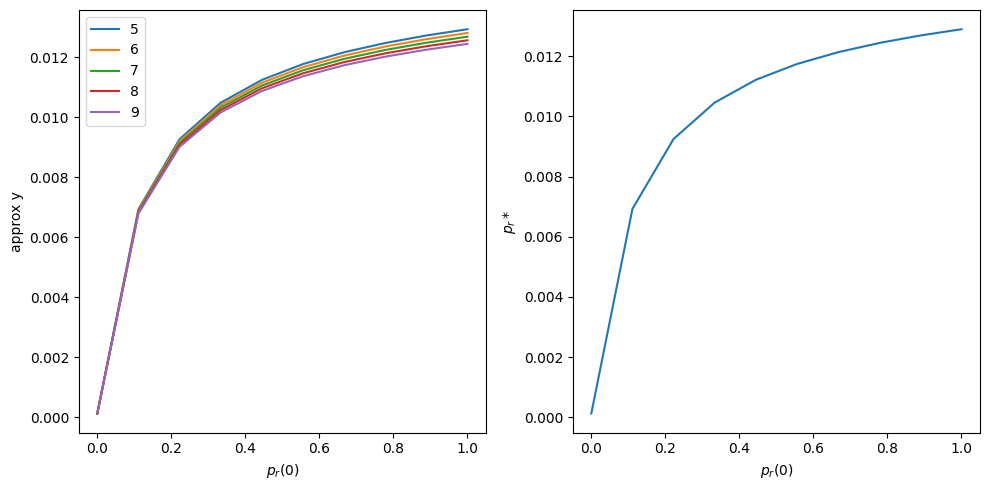

In [26]:
fig, ax = plt.subplots(1,2, figsize =(10,5))
for species in range(l.shape[0]): 
    ax[0].plot(Rs, results[:,species], label = l[species])
ax[1].plot(Rs,r_res)
ax[0].set_xlabel('$p_r(0)$')
ax[0].set_ylabel('approx y')
ax[1].set_xlabel('$p_r(0)$')
ax[1].set_ylabel('$p_r*$')
ax[0].legend()
fig.tight_layout()
plt.show()